# Chapter 9: Modeling Probabilities and Nonlinearities
## Activation Functions

**Book:** Grokking Deep Learning
**Author:** Andrew W. Trask

### Learning Objectives
- Understand the purpose of activation functions.
- Learn standard hidden-layer activation functions.
- Learn standard output-layer activation functions.
- Understand softmax computation.
- Understand derivatives of activation functions.
- Apply activation functions to an MNIST neural network.

## 1. What Is an Activation Function?

Activation function adalah fungsi yang diterapkan pada nilai
neuron selama proses prediksi.

Fungsi ini mengubah nilai masukan suatu neuron menjadi nilai
keluaran tertentu. Pada chapter sebelumnya, ReLU telah digunakan
untuk mengubah nilai negatif menjadi nol.

Activation function membantu neural network mempelajari hubungan
nonlinear pada data. Tanpa nonlinearitas yang sesuai, penambahan
beberapa layer linear tidak memberikan kemampuan representasi
yang sama seperti jaringan dengan fungsi aktivasi nonlinear.

Fungsi aktivasi yang digunakan perlu disesuaikan dengan kebutuhan
hidden layer maupun output layer.

## 2. Standard Hidden-Layer Activation Functions

Dua fungsi aktivasi hidden layer yang dibahas pada chapter ini
adalah sigmoid dan tanh.

### Sigmoid

Sigmoid mengubah nilai masukan menjadi nilai antara 0 dan 1.

Rumus:

sigmoid(x) = 1 / (1 + exp(-x))

### Tanh

Tanh mengubah nilai masukan menjadi nilai antara -1 dan 1.

Rumus:

tanh(x) = tanh(x)

Kedua fungsi tersebut memiliki keluaran nonlinear. Namun, ketika
masukan terlalu besar atau terlalu kecil, kemiringan kurvanya
mendekati nol. Hal ini dapat memengaruhi besarnya pembaruan weight
selama proses pembelajaran.

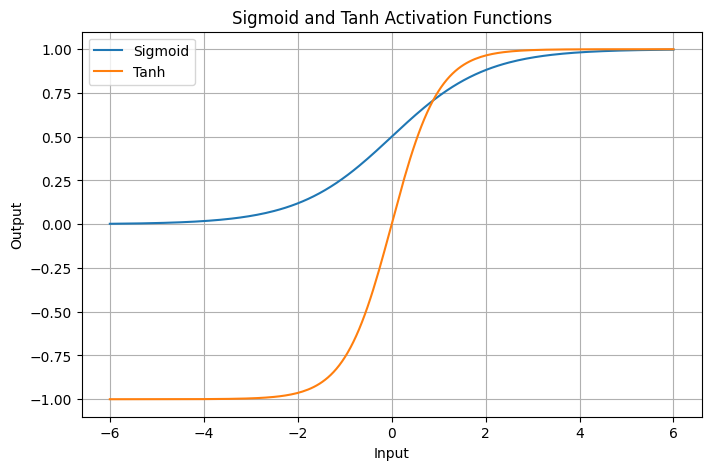

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

x = np.linspace(-6, 6, 200)

plt.figure(figsize=(8, 5))
plt.plot(x, sigmoid(x), label="Sigmoid")
plt.plot(x, tanh(x), label="Tanh")
plt.xlabel("Input")
plt.ylabel("Output")
plt.title("Sigmoid and Tanh Activation Functions")
plt.legend()
plt.grid(True)
plt.show()

## 3. Standard Output-Layer Activation Functions

Pemilihan fungsi aktivasi output bergantung pada jenis prediksi
yang ingin dihasilkan.

### Raw Data Values

Untuk prediksi nilai numerik yang tidak dibatasi pada rentang
probabilitas, output dapat menggunakan nilai linear tanpa fungsi
aktivasi.

### Sigmoid

Sigmoid cocok untuk memodelkan probabilitas biner yang dinilai
secara terpisah pada setiap output, misalnya beberapa label
yang masing-masing dapat benar atau salah.

### Softmax

Softmax digunakan ketika model perlu memilih satu kelas dari
beberapa kelas yang saling bersaing, seperti klasifikasi angka
0 sampai 9 pada dataset MNIST.

## 4. The Core Issue: Inputs Have Similarity

Dalam klasifikasi, data yang berbeda dapat memiliki pola yang
mirip. Neural network perlu menghasilkan prediksi yang sesuai
dengan pola tersebut, bukan hanya menghafal setiap contoh.

Pada klasifikasi MNIST, setiap gambar hanya memiliki satu label
angka yang benar. Jika model memprediksi bahwa sebuah gambar
adalah angka 9 dengan probabilitas tinggi, probabilitas untuk
kelas angka lainnya seharusnya menjadi lebih rendah.

Karakteristik ini menjadi alasan penggunaan softmax pada output
layer untuk klasifikasi multikelas dengan satu label yang benar.

## 5. Softmax Computation

Softmax mengubah sekumpulan nilai output menjadi probabilitas
yang jumlahnya sama dengan 1.

Rumus:

softmax(x_i) = exp(x_i) / sum(exp(x_j))

Tahapan perhitungannya:
1. Menghitung eksponensial dari setiap nilai output.
2. Menjumlahkan seluruh nilai eksponensial.
3. Membagi setiap nilai eksponensial dengan jumlah tersebut.

Nilai softmax yang lebih besar menunjukkan bahwa kelas tersebut
mendapatkan probabilitas prediksi yang lebih tinggi.

Dalam implementasi numerik, nilai maksimum input biasanya
dikurangi terlebih dahulu sebelum eksponensial dihitung untuk
mengurangi risiko overflow.

In [2]:
def softmax(x):
    # Mengurangi nilai maksimum untuk stabilitas numerik
    shifted_x = x - np.max(x, axis=-1, keepdims=True)
    exp_x = np.exp(shifted_x)
    return exp_x / np.sum(exp_x, axis=-1, keepdims=True)

# Contoh output dari tiga kelas
logits = np.array([[1.2, 0.3, 2.1]])

probabilities = softmax(logits)

print("Logits:")
print(logits)

print("\nSoftmax probabilities:")
print(probabilities)

print("\nTotal probability:")
print(np.sum(probabilities))

Logits:
[[1.2 0.3 2.1]]

Softmax probabilities:
[[0.25865373 0.10516076 0.63618551]]

Total probability:
0.9999999999999999


## 6. Activation Installation Instructions

Fungsi aktivasi diterapkan setelah operasi perkalian antara
nilai layer sebelumnya dan matriks weight.

Contoh forward propagation:

layer_1 = tanh(layer_0.dot(weights_0_1))

layer_2 = softmax(layer_1.dot(weights_1_2))

Ketika fungsi aktivasi digunakan, proses backpropagation juga
harus memperhitungkan turunannya.

Delta dari layer berikutnya diteruskan melalui matriks weight,
kemudian disesuaikan dengan turunan fungsi aktivasi pada layer
yang sedang diperbarui.

## 7. Multiplying Delta by the Slope

Dalam backpropagation, delta menunjukkan arah dan besarnya
koreksi yang diperlukan untuk memperbaiki prediksi.

Ketika sebuah layer menggunakan fungsi aktivasi nonlinear,
delta dari layer berikutnya perlu disesuaikan dengan turunan
fungsi aktivasi tersebut.

Untuk tanh, turunannya dapat dihitung menggunakan output aktivasi:

tanh_derivative = 1 - output^2

Penyesuaian ini membantu memperhitungkan seberapa besar perubahan
input dapat memengaruhi output neuron.

In [3]:
def sigmoid_derivative(output):
    return output * (1 - output)

def tanh_derivative(output):
    return 1 - output**2

def relu_derivative(output):
    return (output > 0).astype(float)

values = np.array([-2.0, -1.0, 0.0, 1.0, 2.0])

sigmoid_output = sigmoid(values)
tanh_output = tanh(values)
relu_output = np.maximum(0, values)

print("Sigmoid output:")
print(sigmoid_output)
print("Sigmoid derivative:")
print(sigmoid_derivative(sigmoid_output))

print("\nTanh output:")
print(tanh_output)
print("Tanh derivative:")
print(tanh_derivative(tanh_output))

print("\nReLU output:")
print(relu_output)
print("ReLU derivative:")
print(relu_derivative(relu_output))

Sigmoid output:
[0.11920292 0.26894142 0.5        0.73105858 0.88079708]
Sigmoid derivative:
[0.10499359 0.19661193 0.25       0.19661193 0.10499359]

Tanh output:
[-0.96402758 -0.76159416  0.          0.76159416  0.96402758]
Tanh derivative:
[0.07065082 0.41997434 1.         0.41997434 0.07065082]

ReLU output:
[0. 0. 0. 1. 2.]
ReLU derivative:
[0. 0. 0. 1. 1.]


## 8. Converting Output to Slope (Derivative)

Beberapa fungsi aktivasi memungkinkan turunannya dihitung
langsung dari output aktivasi yang telah diperoleh pada
forward propagation.

Contohnya:

- Sigmoid: output × (1 - output)
- Tanh: 1 - output²
- ReLU: menggunakan indikator apakah nilai aktivasi positif

Cara ini membantu menghitung delta selama backpropagation tanpa
harus menghitung ulang seluruh fungsi dari awal.

Untuk output layer dengan softmax pada klasifikasi multikelas,
delta memiliki bentuk khusus yang berkaitan dengan perbedaan
antara label target dan probabilitas prediksi.

## 9. Upgrading the MNIST Network

Pada bagian ini, jaringan klasifikasi MNIST diperbarui dengan
menggunakan tanh sebagai fungsi aktivasi hidden layer dan softmax
sebagai fungsi aktivasi output layer.

MNIST berisi gambar angka tulisan tangan dari 0 sampai 9.
Setiap gambar berukuran 28 × 28 piksel dan diubah menjadi
vektor dengan 784 nilai.

Output jaringan terdiri dari 10 nilai yang mewakili kelas angka
0 sampai 9. Kelas dengan probabilitas tertinggi dipilih sebagai
prediksi model.

Pengaturan weight awal dan learning rate perlu disesuaikan
dengan fungsi aktivasi yang digunakan. Hasil akurasi juga
bergantung pada jumlah data dan proses training.

In [4]:
from tensorflow.keras.datasets import mnist

# Memuat dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Menggunakan subset untuk demonstrasi
num_train = 1000
num_test = 1000

images = x_train[:num_train].reshape(num_train, 784).astype("float32") / 255.0
test_images = x_test[:num_test].reshape(num_test, 784).astype("float32") / 255.0

labels = np.eye(10)[y_train[:num_train]]
test_labels = np.eye(10)[y_test[:num_test]]

print("Training images:", images.shape)
print("Training labels:", labels.shape)
print("Testing images:", test_images.shape)
print("Testing labels:", test_labels.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (1000, 784)
Training labels: (1000, 10)
Testing images: (1000, 784)
Testing labels: (1000, 10)


In [5]:
np.random.seed(1)

# Pengaturan model
alpha = 0.1
iterations = 30
hidden_size = 100
batch_size = 100

# Inisialisasi weight
weights_0_1 = (
    0.02 * np.random.random((784, hidden_size)) - 0.01
)
weights_1_2 = (
    0.2 * np.random.random((hidden_size, 10)) - 0.1
)

for epoch in range(iterations):
    correct_count = 0

    # Mengacak urutan data setiap epoch
    order = np.random.permutation(len(images))

    for start in range(0, len(images), batch_size):
        batch_indices = order[start:start + batch_size]

        layer_0 = images[batch_indices]
        batch_labels = labels[batch_indices]

        # Forward propagation
        layer_1 = np.tanh(layer_0.dot(weights_0_1))
        layer_2 = softmax(layer_1.dot(weights_1_2))

        correct_count += np.sum(
            np.argmax(layer_2, axis=1)
            == np.argmax(batch_labels, axis=1)
        )

        # Delta output
        layer_2_delta = (
            batch_labels - layer_2
        ) / len(batch_indices)

        # Delta hidden layer
        layer_1_delta = (
            layer_2_delta.dot(weights_1_2.T)
            * (1 - layer_1**2)
        )

        # Update weight
        weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 += alpha * layer_0.T.dot(layer_1_delta)

    train_accuracy = correct_count / len(images)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Training accuracy: {train_accuracy:.4f}"
    )

Epoch 01 | Training accuracy: 0.4850
Epoch 02 | Training accuracy: 0.7410
Epoch 03 | Training accuracy: 0.7390
Epoch 04 | Training accuracy: 0.7660
Epoch 05 | Training accuracy: 0.7970
Epoch 06 | Training accuracy: 0.8190
Epoch 07 | Training accuracy: 0.8400
Epoch 08 | Training accuracy: 0.8590
Epoch 09 | Training accuracy: 0.8580
Epoch 10 | Training accuracy: 0.8780
Epoch 11 | Training accuracy: 0.8860
Epoch 12 | Training accuracy: 0.8860
Epoch 13 | Training accuracy: 0.8910
Epoch 14 | Training accuracy: 0.8960
Epoch 15 | Training accuracy: 0.9000
Epoch 16 | Training accuracy: 0.9040
Epoch 17 | Training accuracy: 0.9070
Epoch 18 | Training accuracy: 0.9140
Epoch 19 | Training accuracy: 0.9180
Epoch 20 | Training accuracy: 0.9210
Epoch 21 | Training accuracy: 0.9230
Epoch 22 | Training accuracy: 0.9260
Epoch 23 | Training accuracy: 0.9260
Epoch 24 | Training accuracy: 0.9220
Epoch 25 | Training accuracy: 0.9310
Epoch 26 | Training accuracy: 0.9310
Epoch 27 | Training accuracy: 0.9350
E

In [6]:
# Evaluasi tanpa pembaruan weight
test_hidden = np.tanh(test_images.dot(weights_0_1))
test_output = softmax(test_hidden.dot(weights_1_2))

predictions = np.argmax(test_output, axis=1)
actual_labels = np.argmax(test_labels, axis=1)

test_accuracy = np.mean(predictions == actual_labels)

print(f"Testing accuracy: {test_accuracy:.4f}")

# Menampilkan contoh prediksi
for i in range(10):
    print(
        f"Actual: {actual_labels[i]} | "
        f"Predicted: {predictions[i]} | "
        f"Probabilities: {np.round(test_output[i], 3)}"
    )

Testing accuracy: 0.8420
Actual: 7 | Predicted: 7 | Probabilities: [0.001 0.    0.001 0.004 0.    0.    0.    0.986 0.    0.009]
Actual: 2 | Predicted: 6 | Probabilities: [0.088 0.005 0.28  0.027 0.    0.207 0.357 0.    0.034 0.   ]
Actual: 1 | Predicted: 1 | Probabilities: [0.    0.935 0.03  0.005 0.    0.001 0.005 0.009 0.012 0.002]
Actual: 0 | Predicted: 0 | Probabilities: [0.972 0.    0.003 0.    0.    0.015 0.006 0.003 0.    0.001]
Actual: 4 | Predicted: 4 | Probabilities: [0.001 0.    0.018 0.001 0.894 0.001 0.014 0.011 0.006 0.053]
Actual: 1 | Predicted: 1 | Probabilities: [0.    0.94  0.019 0.005 0.    0.    0.001 0.019 0.013 0.002]
Actual: 4 | Predicted: 4 | Probabilities: [0.    0.    0.    0.011 0.897 0.012 0.001 0.002 0.015 0.063]
Actual: 9 | Predicted: 9 | Probabilities: [0.    0.021 0.001 0.02  0.125 0.021 0.015 0.022 0.037 0.738]
Actual: 5 | Predicted: 2 | Probabilities: [0.016 0.007 0.627 0.    0.023 0.006 0.31  0.    0.011 0.001]
Actual: 9 | Predicted: 9 | Probabilitie

## 10. Summary

Chapter 9 membahas penggunaan activation functions untuk
menghasilkan nonlinearitas dan memodelkan probabilitas dalam
neural network.

Materi utama:

1. Activation function diterapkan pada neuron selama prediksi.
2. Sigmoid dan tanh merupakan fungsi aktivasi yang dapat digunakan
   pada hidden layer.
3. Softmax digunakan untuk mengubah output menjadi probabilitas
   pada klasifikasi multikelas.
4. Delta pada backpropagation perlu memperhitungkan turunan
   fungsi aktivasi.
5. Turunan sigmoid dan tanh dapat dihitung dari output aktivasi.
6. Jaringan MNIST dapat diperbarui menggunakan tanh pada hidden
   layer dan softmax pada output layer.

Pemilihan fungsi aktivasi memengaruhi proses pembelajaran dan
cara model menghasilkan prediksi.